# Assignmet 1

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import copy
import warnings
warnings.filterwarnings('ignore')

In [2]:
def minmax_normalize(img):
    """Normalize image to [0, 1] range.
    
    Args:
        img: Input image (any range).
        
    Returns:
        Normalized image (float32 in range [0,1]).
    """
    return cv2.normalize(img, None, 0, 1, cv2.NORM_MINMAX, dtype=cv2.CV_32F)

## Question 1

In computer vision, image zooming is a process that enlarges or reduces an image while preserving or altering its details.

You are provided with an image *einstein.jpg*, and your task is to apply zooming with a factor of 2 using the following two methods: **Pixel replication** and **Zero-order hold**.


**A)** Describe each of the two methods (Pixel replication, Zero-order hold) for image zooming.

**B)** Implement Python code to perform zooming in on the image 'einstein.jpg' using a zoom factor of 2 for each of the two methods. Provide step-by-step explanations of your code for each method.

**C)** For each of the two methods, discuss their advantages and disadvantages. Consider aspects such as image quality, computational complexity, and suitability for different types of images.

**D)** Display the zoomed images for the two methods and report the results. Examine the effects of increasing the zoom factor (e.g., from 2 to 4) on image quality and detail preservation.

**E)** Suggest an improved zooming method and compare its results with the two experimented methods.

You can see the original form of the image below

<img src="./imgs/einstein.jpg"/>

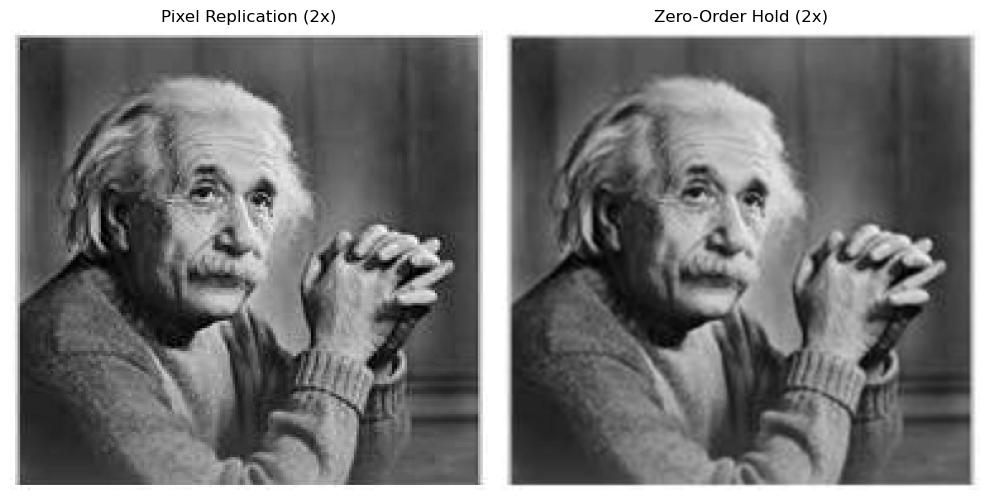

In [3]:
# For this question, OpenCV is better suited for displaying images. Matplotlib is used for cell graphical output.

# Answer for B : Zooming Using a zoom factor of 2 for each method

ex1_image = cv2.imread('./imgs/einstein.jpg', cv2.IMREAD_GRAYSCALE)

# Pixel Replication (Nearest Neighbor)
pixel_repl_x2 = cv2.resize(ex1_image, None, fx=2, fy=2, interpolation=cv2.INTER_NEAREST)

# Zero-Order Hold (Bilinear Interpolation)
zoh_x2 = cv2.resize(ex1_image, None, fx=2, fy=2, interpolation=cv2.INTER_LINEAR)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(pixel_repl_x2, cmap='gray')
plt.title('Pixel Replication (2x)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(zoh_x2, cmap='gray')
plt.title('Zero-Order Hold (2x)')
plt.axis('off')

plt.tight_layout()

#plt.savefig('./results/einstein2x.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

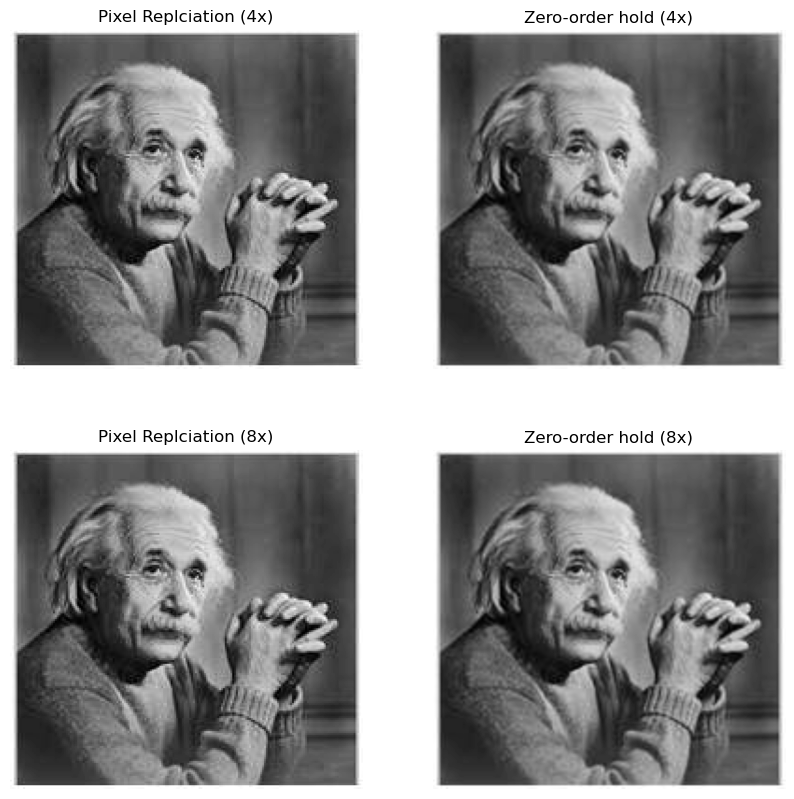

In [4]:
#Answer for D : Higher Zoom Factors

#4x Zoom Factor
pixel_repl_x4 = cv2.resize(ex1_image,None, fx=4, fy=4, interpolation=cv2.INTER_NEAREST)
zoh_x4 = cv2.resize(ex1_image,None, fx=4, fy=4, interpolation=cv2.INTER_LINEAR)

#8x Zoom Factor
pixel_repl_x8 = cv2.resize(ex1_image,None, fx=8, fy=8, interpolation=cv2.INTER_NEAREST)
zoh_x8 = cv2.resize(ex1_image,None, fx=8, fy=8, interpolation=cv2.INTER_LINEAR)

plt.figure(figsize=(10,10))

plt.subplot(2,2,1)
plt.title('Pixel Replciation (4x)')
plt.axis('off')
plt.imshow(pixel_repl_x4, cmap='gray')

plt.subplot(2,2,2)
plt.title('Zero-order hold (4x)')
plt.axis('off')
plt.imshow(zoh_x4, cmap='gray')

plt.subplot(2,2,3)
plt.title('Pixel Replciation (8x)')
plt.axis('off')
plt.imshow(pixel_repl_x8, cmap='gray')

plt.subplot(2,2,4)
plt.title('Zero-order hold (8x)')
plt.axis('off')
plt.imshow(zoh_x8, cmap='gray');

#plt.savefig('./results/einstein4x8x.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

In [5]:
#Calculate and print number of differing pixels between interpolated and reference images
print('Number of different pixels in 2x: ', sum(sum(pixel_repl_x2 != zoh_x2)))
print('Number of different pixels in 4x: ', sum(sum(pixel_repl_x4 != zoh_x4)))
print('Number of different pixels in 8x: ', sum(sum(pixel_repl_x8 != zoh_x8)))

Number of different pixels in 2x:  107158
Number of different pixels in 4x:  418214
Number of different pixels in 8x:  1662714


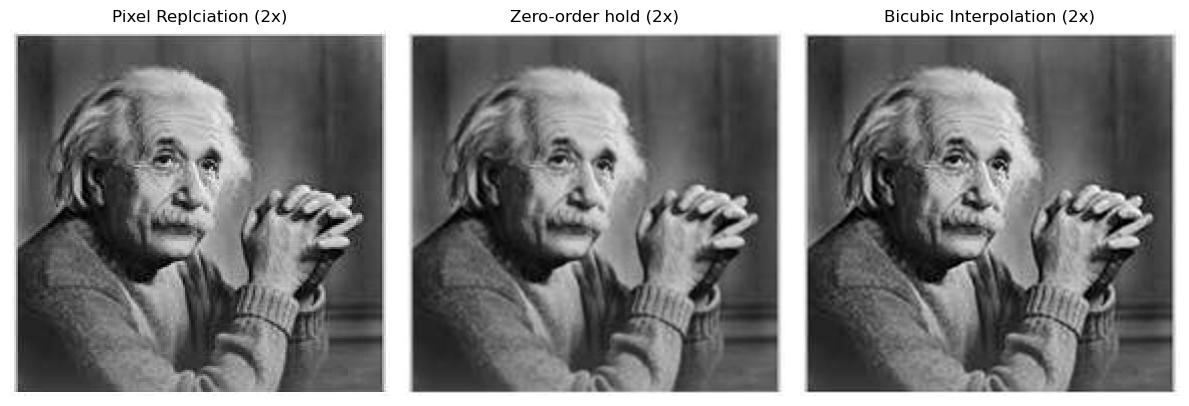

In [6]:
# Answer for E :Improved Method - Bicubic

# Advanced interpolation comparison
bicubic_x2 = cv2.resize(ex1_image, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)

plt.figure(figsize=(12, 4))

plt.subplot(1,3,1)
plt.title('Pixel Replciation (2x)')
plt.axis('off')
plt.imshow(pixel_repl_x2, cmap='gray')

plt.subplot(1,3,2)
plt.title('Zero-order hold (2x)')
plt.axis('off')
plt.imshow(zoh_x2, cmap='gray')

plt.subplot(1,3,3)
plt.title('Bicubic Interpolation (2x)')
plt.axis('off')
plt.imshow(bicubic_x2, cmap='gray')

plt.tight_layout()
#plt.savefig('./results/einstein2xcomparison.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

## Question 2

You are given a low-contrast grayscale image, 'low_contrast.jpg', which has lost significant details due to insufficient contrast. Your task is to enhance the image using logarithmic and gamma correction techniques. Additionally, you need to plot the histograms of the original and enhanced images for comparison.

<img src="./imgs/low_contrast.jpg" width="200" height="200"/>

**A)** Normalize the image to ensure its pixel values are within range (0 to 1).

**B)** Describe each of the two methods (Logarithmic correction and Gamma correction) for contrast stretching.

**C)** Apply logarithmic contrast stretching to 'low_contrast.jpg' using the formula:

enhanced_pixel_value = c * log(1 + original_pixel_value)

Choose an appropriate constant 'c' to scale the enhanced pixel values to the range (0 to 1).

**D)** Apply gamma correction to 'low_contrast.jpg'.
Choose a suitable 'gamma' value for enhancing the image's contrast.

**E)** After applying both contrast enhancement techniques, plot histograms for the original and enhanced images on a single figure.

*X-axis:* Pixel intensity values (0 to 1)  
*Y-axis:* Frequency of each intensity value in the image

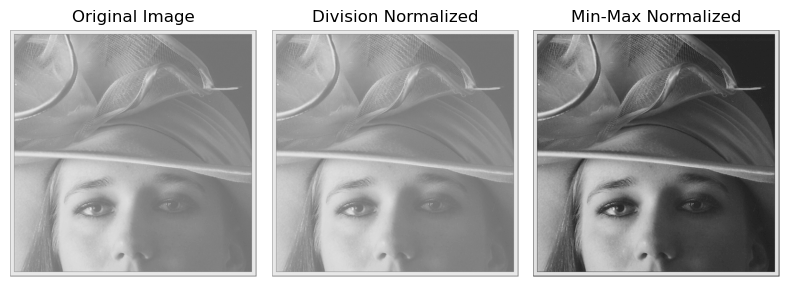

In [7]:
# Answer for A: Image Normalization to [0, 1] Range

# The input image has pixel values in range [94, 251]. Two normalization methods are compared:
# 1. Division by 255 (preserves original contrast)
# 2. Min-max scaling (changes the original contrast)

ex2_image = cv2.imread('./imgs/low_contrast.jpg', cv2.IMREAD_GRAYSCALE)

ex2_image_normalized_minmax = minmax_normalize(ex2_image)  # Min-max scaling
ex2_image_normalized_div = ex2_image / 255.0               # Simple scaling

plt.figure(figsize=(8, 4))
plt.subplot(1, 3, 1)
plt.imshow(ex2_image, cmap='gray', vmin=0, vmax=255)
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(ex2_image_normalized_div, cmap='gray', vmin=0, vmax=1)
plt.title('Division Normalized')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(ex2_image_normalized_minmax, cmap='gray', vmin=0, vmax=1)
plt.title('Min-Max Normalized')
plt.axis('off')

plt.tight_layout()

#plt.savefig('./results/q2compare.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

In [8]:
def logarithmic_correction(image, c):
    """Apply logarithmic correction to enhance contrast.
    
    Args:
        image: Input normalized image [0, 1].
        c: Scaling constant.
        
    Returns:
        Corrected image with enhanced contrast.
    """
    return c * np.log1p(image)

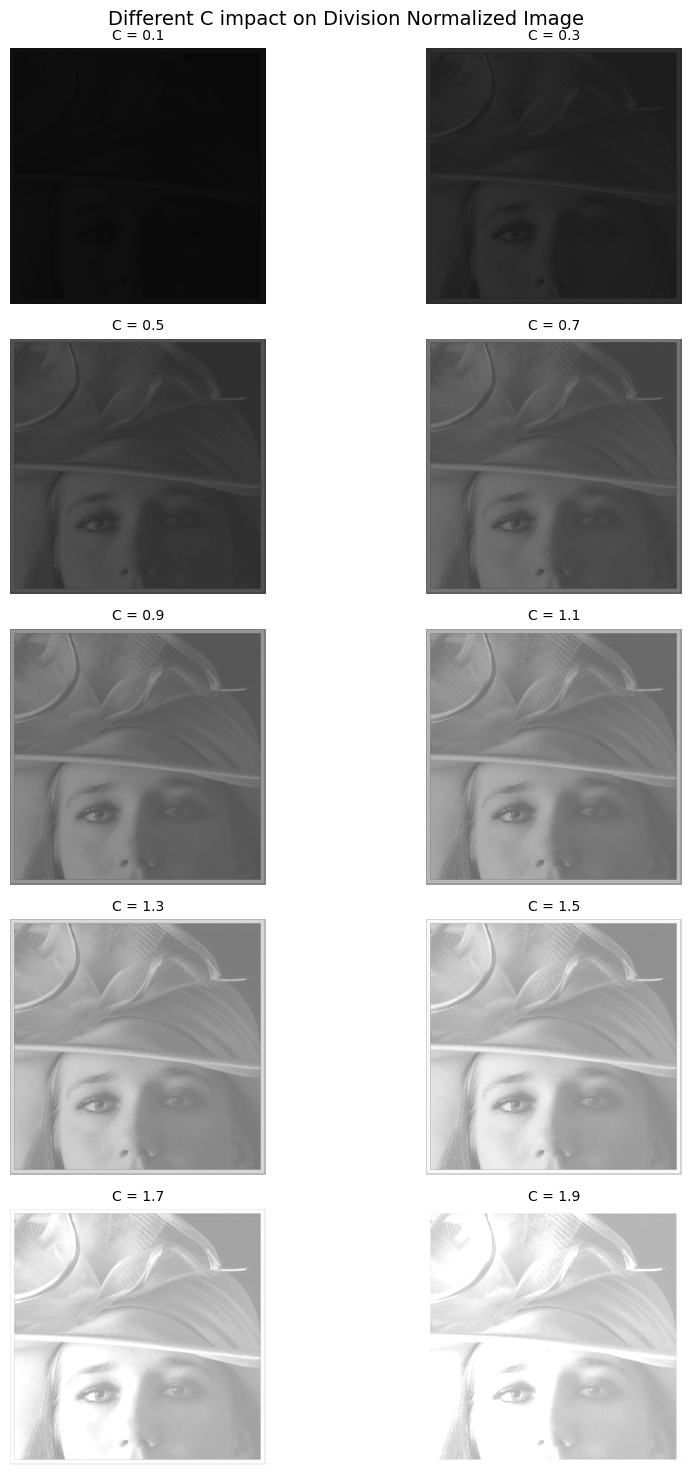

In [9]:
# Answer for C: Logarithmic Contrast Stretching

# Testing C in range [0.1, 2.0] (step=0.2) on division-normalized image
# Shows effect of scaling constant on contrast enhancement

images = [logarithmic_correction(ex2_image_normalized_div, c) for c in np.arange(0.1, 2.1, 0.2)]

# Create subplot grid
fig, axs = plt.subplots(5, 2, figsize=(10, 15))
for ax, img, c in zip(axs.ravel(), images, np.arange(0.1, 2.1, 0.2)):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"C = {c:.1f}", fontsize=10)
    ax.axis('off')

plt.suptitle("Different C impact on Division Normalized Image", fontsize=14)
plt.tight_layout()
plt.show()

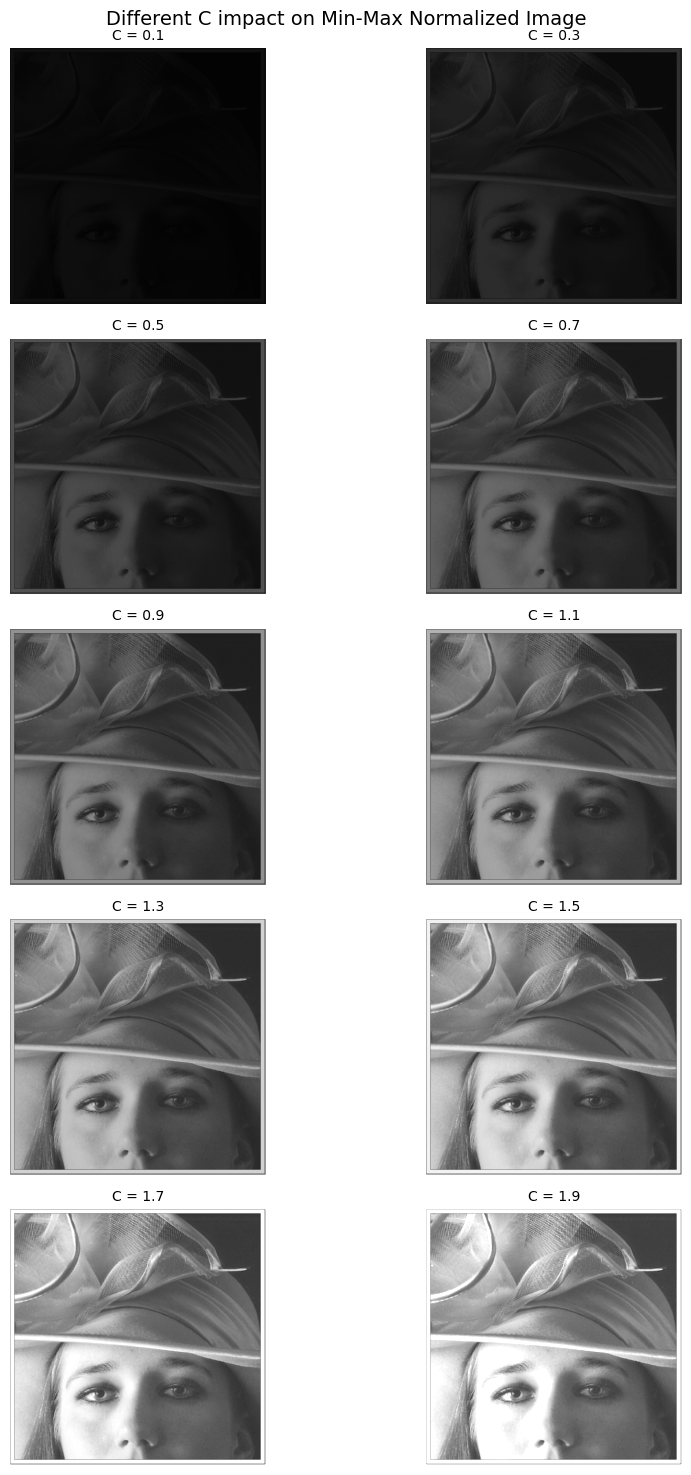

In [10]:
# Same as previous cell but for min-max normalized image
images = [logarithmic_correction(ex2_image_normalized_minmax, c) 
          for c in np.arange(0.1, 2.1, 0.2)]

fig, axs = plt.subplots(5, 2, figsize=(10, 15))
for ax, img, c in zip(axs.ravel(), images, np.arange(0.1, 2.1, 0.2)):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"C = {c:.1f}", fontsize=10)
    ax.axis('off')

plt.suptitle("Different C impact on Min-Max Normalized Image", fontsize=14)
plt.tight_layout()
plt.show()

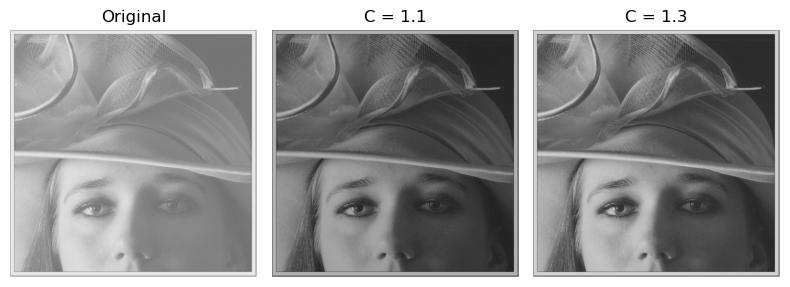

In [11]:
# Compare optimal C values (1.1 vs 1.3) for min-max normalized image

plt.figure(figsize=(8, 4))

plt.subplot(1, 3, 1)
plt.imshow(ex2_image, cmap='gray', vmin=0, vmax=255)
plt.title('Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(logarithmic_correction(ex2_image_normalized_minmax, 1.1), cmap='gray', vmin=0, vmax=1)
plt.title('C = 1.1')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(logarithmic_correction(ex2_image_normalized_minmax, 1.3), cmap='gray', vmin=0, vmax=1)
plt.title('C = 1.3')
plt.axis('off')

plt.tight_layout()

#plt.savefig('./results/q2compare2.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

In [12]:
def piecewise_gamma_correction(img, r1=0.1, r2=0.9, gamma=2):
    """
    Apply piecewise gamma correction.

    Intensities below r1 are mapped to 0, while intensities
    above r2 are mapped to 1. Gamma correction is applied
    to the remaining intensity values.
    """

    result = np.where(img < r1, 0, img)
    result = np.where(img > r2, 1, result)

    mask = (img >= r1) & (img <= r2)

    result[mask] = ((img[mask] - r1) / (r2 - r1)) ** gamma

    return result


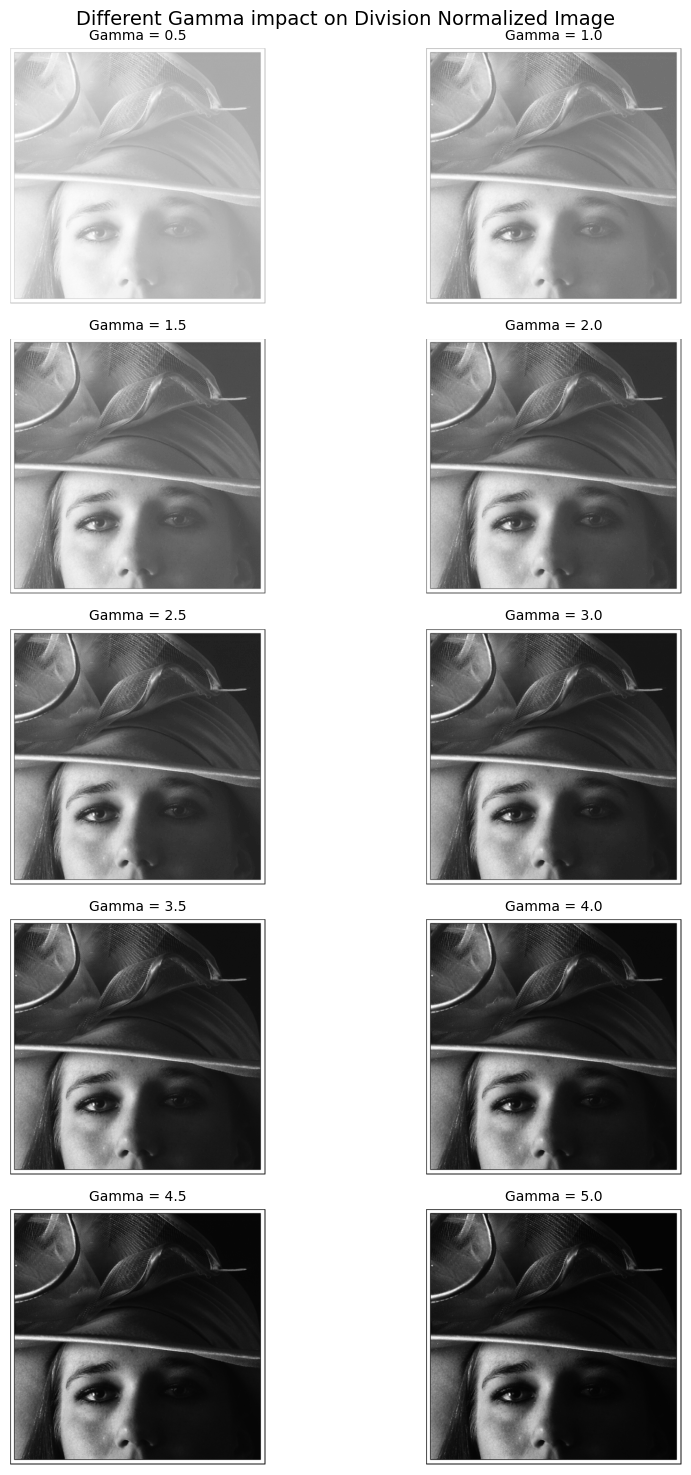

In [13]:
# Answer for D: Gamma Correction Analysis

# Testing Gamma in range [0.5, 5.5] (step=0.5) on division-normalized image

gammas = np.arange(0.5, 6.0, 0.5)
images = [piecewise_gamma_correction(ex2_image_normalized_div, gamma=g) for g in gammas]

fig, axs = plt.subplots(5, 2, figsize=(10, 15))
for ax, img, gamma in zip(axs.ravel(), images, gammas):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"Gamma = {gamma:.1f}", fontsize=10)
    ax.axis('off')

plt.suptitle("Different Gamma impact on Division Normalized Image", fontsize=14)
plt.tight_layout()
plt.show()

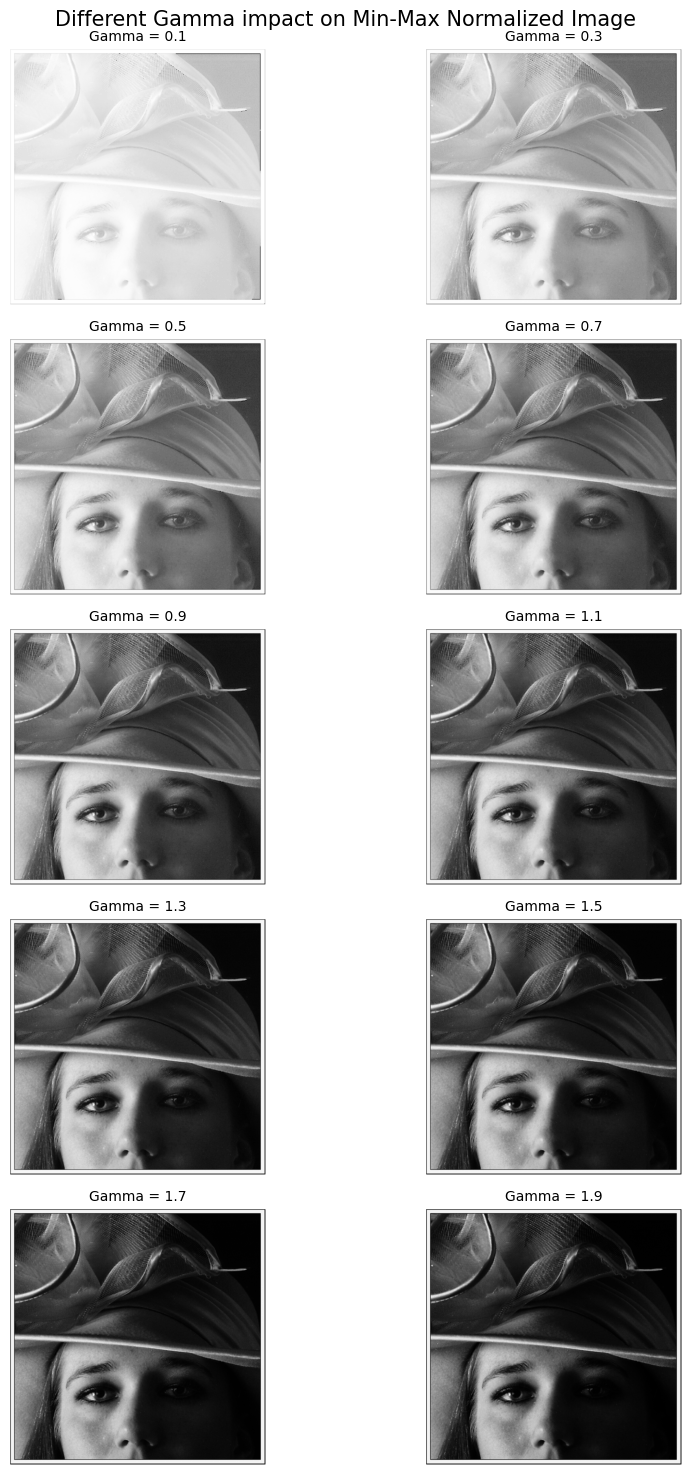

In [14]:
# Gamma correction applied to min-max normalized image
# Testing Gamma in range [0.1, 1.9] (step=0.2) on min-max normalized image

gammas = np.arange(0.1, 2, 0.2)
images = [piecewise_gamma_correction(ex2_image_normalized_minmax, gamma=g) for g in gammas]

fig, axs = plt.subplots(5, 2, figsize=(10, 15))
for ax, img, gamma in zip(axs.ravel(), images, gammas):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"Gamma = {gamma:.1f}", fontsize=10)
    ax.axis('off')

plt.suptitle("Different Gamma impact on Min-Max Normalized Image", fontsize=15)
plt.tight_layout()
plt.show()

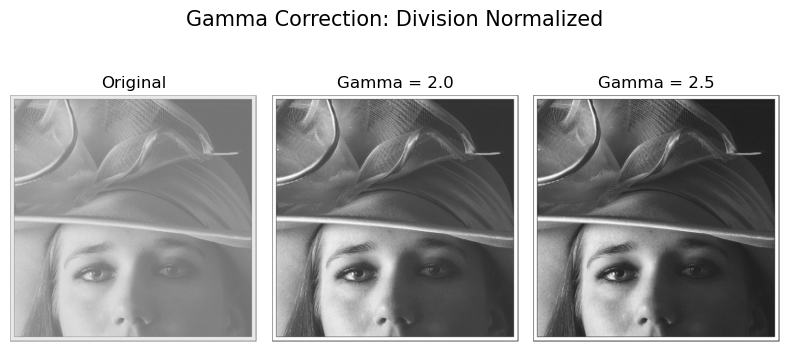

In [15]:
# Compare optimal gamma values for division-normalized image

plt.figure(figsize=(8, 4))

plt.subplot(1, 3, 1)
plt.imshow(ex2_image, cmap='gray', vmin=0, vmax=255)
plt.title('Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(piecewise_gamma_correction(ex2_image_normalized_div, gamma=2.0), cmap='gray', vmin=0, vmax=1)
plt.title('Gamma = 2.0')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(piecewise_gamma_correction(ex2_image_normalized_div, gamma=2.5), cmap='gray', vmin=0, vmax=1)
plt.title('Gamma = 2.5')
plt.axis('off')

plt.suptitle("Gamma Correction: Division Normalized", fontsize=15)
plt.tight_layout()

#plt.savefig('./results/q2compare3.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

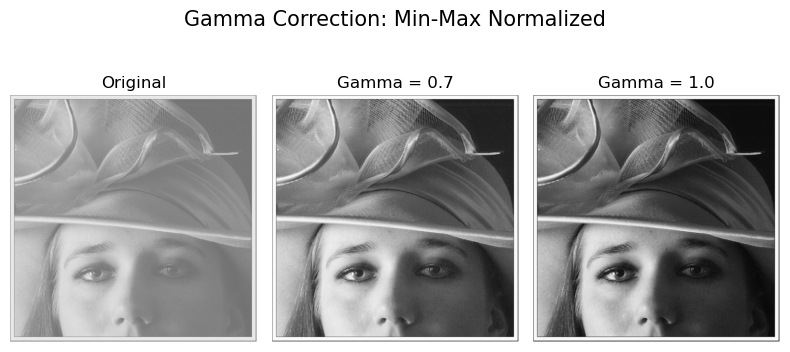

In [16]:
# Compare optimal gamma values for min-max normalized image

plt.figure(figsize=(8, 4))

plt.subplot(1, 3, 1)
plt.imshow(ex2_image, cmap='gray', vmin=0, vmax=255)
plt.title('Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(piecewise_gamma_correction(ex2_image_normalized_minmax, gamma=0.7), cmap='gray', vmin=0, vmax=1)
plt.title('Gamma = 0.7')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(piecewise_gamma_correction(ex2_image_normalized_minmax, gamma=1.0), cmap='gray', vmin=0, vmax=1)
plt.title('Gamma = 1.0')
plt.axis('off')

plt.suptitle("Gamma Correction: Min-Max Normalized", fontsize=15)
plt.tight_layout()

#plt.savefig('./results/q2compare4.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

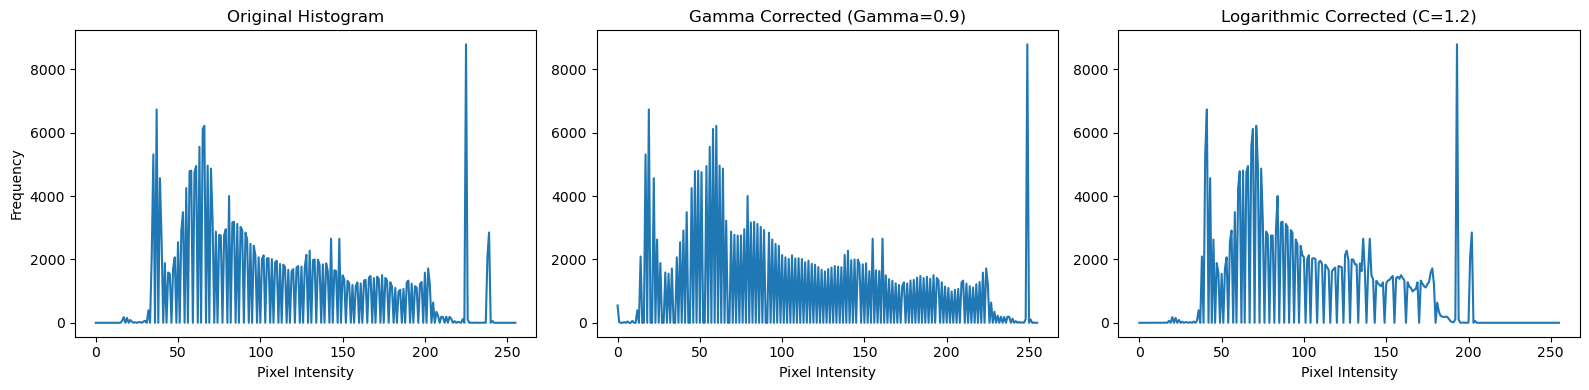

In [17]:
# Answer for E: Histogram Comparison (Min-max normalized image)

# Compares original vs enhanced images using: Gamma correction (Gamma=0.9) & Logarithmic correction (C=1.2)

plt.figure(figsize=(16, 4))

# Original histogram
plt.subplot(1, 3, 1)
hist = cv2.calcHist([ex2_image_normalized_minmax], [0], None, [256], [0, 1])
plt.plot(hist)
plt.title('Original Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')

# Gamma corrected histogram
plt.subplot(1, 3, 2)
hist = cv2.calcHist([piecewise_gamma_correction(ex2_image_normalized_minmax, gamma=0.9)], [0], None, [256], [0, 1])
plt.plot(hist)
plt.title('Gamma Corrected (Gamma=0.9)')
plt.xlabel('Pixel Intensity')

# Logarithmic corrected histogram
plt.subplot(1, 3, 3)
hist = cv2.calcHist([logarithmic_correction(ex2_image_normalized_minmax, c=1.2)], [0], None, [256], [0, 1])
plt.plot(hist)
plt.title('Logarithmic Corrected (C=1.2)')
plt.xlabel('Pixel Intensity')

plt.tight_layout()

#plt.savefig('./results/q2hists.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

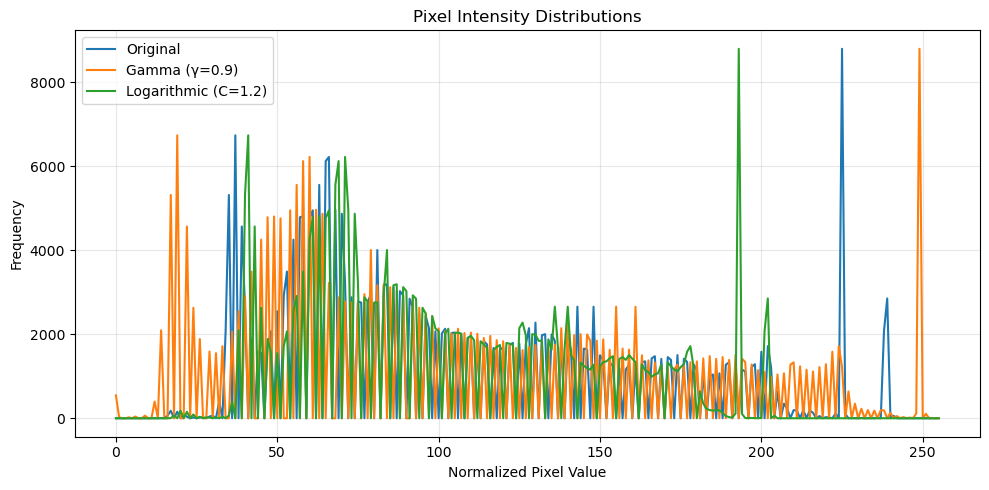

In [18]:
# Overlaid histogram comparison for more clear enhancement analysis
plt.figure(figsize=(10, 5))

# Calculate all histograms
hist_original = cv2.calcHist([ex2_image_normalized_minmax], [0], None, [256], [0, 1])
hist_gamma = cv2.calcHist([piecewise_gamma_correction(ex2_image_normalized_minmax, gamma=0.9)], 
                         [0], None, [256], [0, 1])
hist_log = cv2.calcHist([logarithmic_correction(ex2_image_normalized_minmax, c=1.2)], 
                       [0], None, [256], [0, 1])


plt.plot(hist_original, label='Original')
plt.plot(hist_gamma, label='Gamma (γ=0.9)')
plt.plot(hist_log, label='Logarithmic (C=1.2)')

plt.title('Pixel Intensity Distributions', fontsize=12)
plt.xlabel('Normalized Pixel Value')
plt.ylabel('Frequency')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
# plt.savefig('./results/q2hists1.jpg', format='jpg', bbox_inches="tight", pad_inches=0.01)

## Question 3

Histogram equalization is a technique widely used in image processing to enhance the contrast of an image by redistributing the intensity values. In this question, you will explore the concept of histogram equalization step by step. Use the image below for this question.

<img src="./imgs/lena_gray.gif" width="200" height="200"/>

**A)** Normalize the image to ensure its pixel values are within range (0 to 1).

**B)** Calculate and plot the histogram of the original image. Analyze the histogram to understand the distribution of pixel intensities.

**C)** Implement the histogram equalization algorithm on the original image then calculate and plot the histogram of the equalized image.

**D)** Display the original image, the histogram-equalized image, and their respective histograms side by side for comparison.

**E)** Analyze and compare the visual differences between the original and equalized image. Discuss how histogram equalization has affected the distribution of pixel intensities.

In [19]:
# Answer for A: Image Normalization to [0, 1] Range

# Load gif file and normalize the image
cap = cv2.VideoCapture("./imgs/lena_gray.gif")
_, ex3_image = cap.read()
cap.release()
ex3_image = cv2.cvtColor(ex3_image, cv2.COLOR_BGR2GRAY)
ex3_image_normal = minmax_normalize(ex3_image)

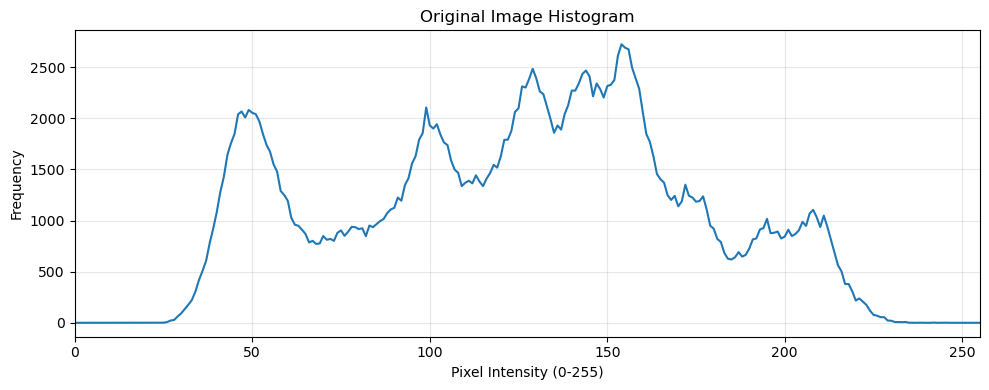

In [20]:
# Answer for B: Plotting the Histogram

# Compute histogram (256 bins for 8-bit image)
hist = cv2.calcHist([ex3_image], [0], None, [256], [0, 256])


plt.figure(figsize=(10, 4))
plt.plot(hist)
plt.title('Original Image Histogram', fontsize=12)
plt.xlabel('Pixel Intensity (0-255)')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.xlim([0, 255])

plt.tight_layout()
#plt.savefig('./results/q3originalhist.jpg', format='jpg', bbox_inches="tight", pad_inches=0.01)

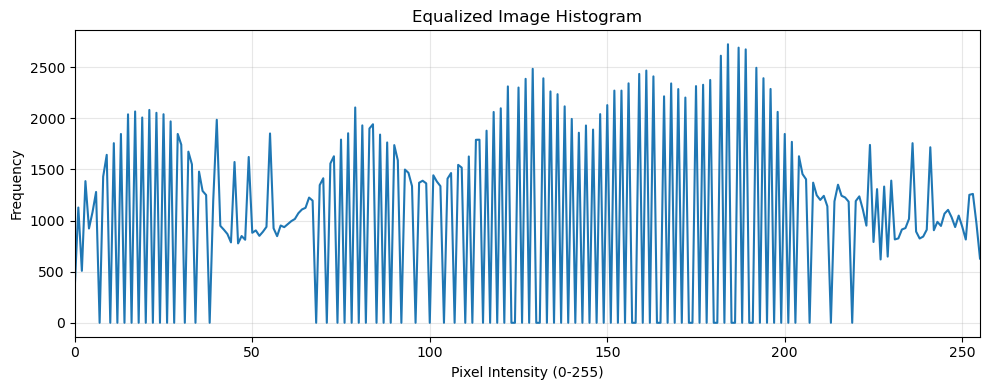

In [21]:
# Answer for C: Histogram Equalization

# Perform histogram equalization
ex3_image_equalized = cv2.equalizeHist(ex3_image)

# Compute equalized histogram
hist_equalized = cv2.calcHist([ex3_image_equalized], [0], None, [256], [0, 256])

plt.figure(figsize=(10, 4))
plt.plot(hist_equalized)
plt.title('Equalized Image Histogram', fontsize=12)
plt.xlabel('Pixel Intensity (0-255)')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.xlim([0, 255])

plt.tight_layout()
# plt.savefig('./results/q3eqhist.jpg', format='jpg', bbox_inches="tight", pad_inches=0.01)

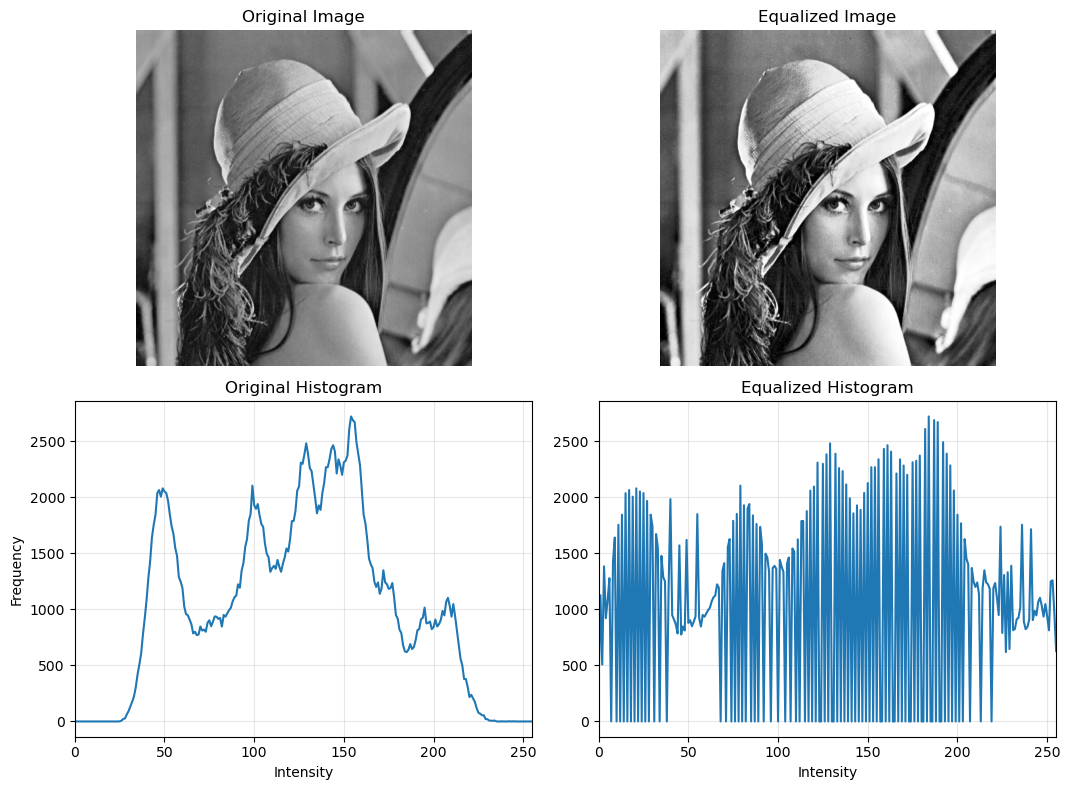

In [22]:
# Answer for D: Results Comparison

# Calculate histograms
hist_original = cv2.calcHist([ex3_image], [0], None, [256], [0, 256])
hist_equalized = cv2.calcHist([ex3_image_equalized], [0], None, [256], [0, 256])

plt.figure(figsize=(16, 8))

plt.subplot(2, 3, 1)
plt.imshow(ex3_image, cmap='gray')
plt.title('Original Image', fontsize=12)
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(ex3_image_equalized, cmap='gray')
plt.title('Equalized Image', fontsize=12)
plt.axis('off')

plt.subplot(2, 3, 4)
plt.plot(hist_original)
plt.title('Original Histogram', fontsize=12)
plt.xlabel('Intensity')
plt.ylabel('Frequency')
plt.xlim([0, 255])
plt.grid(True, alpha=0.3)

plt.subplot(2, 3, 5)
plt.plot(hist_equalized)
plt.title('Equalized Histogram', fontsize=12)
plt.xlabel('Intensity')
plt.xlim([0, 255])
plt.grid(True, alpha=0.3)

plt.tight_layout()

#plt.savefig('./results/q3compare.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

## Question 4

The image square.gif contains two square objects. Pixels in the first square have the intensity 
of 150 while those in the second square have the intensity of 220. Read the image and do the following: 

**A)**  The small square is to be translated by 40 pixels in both directions. 

**B)**  The large square is to be rotated by 60 degrees counter clockwise. 

Write the code to perform these transformations. Show the image before and after transformation on the 
same figure.

you can see the original form of the image below:

<img src="./imgs/square.gif" width="200" height="200"/>

In [23]:
cap = cv2.VideoCapture("./imgs/square.gif")
_, ex4_image = cap.read()
cap.release()

ex4_image = cv2.cvtColor(ex4_image, cv2.COLOR_BGR2GRAY)

small_sq  = copy.deepcopy(ex4_image)
large_sq  = copy.deepcopy(ex4_image)

In [24]:
# Answer for A: Translate small square (150 intensity)

# Isolate small square (values < 160) and translate by (40, 40)

small_sq = np.where(small_sq < 160, small_sq, 0)
translation_matrix = np.float32([[1, 0, 40], 
                               [0, 1, 40]])
small_sq = cv2.warpAffine(small_sq, translation_matrix, 
                         (small_sq.shape[1], small_sq.shape[0]))

In [25]:
# Answer for B: Rotate large square (220 intensity)

# Isolate large square (values > 160) and rotate 60 degrees Counter clockwise

large_sq = np.where(large_sq > 160, large_sq, 0)
rotation_matrix = cv2.getRotationMatrix2D((large_sq.shape[1]/2, large_sq.shape[0]/2), 60, 1)
large_sq = cv2.warpAffine(large_sq, rotation_matrix, (large_sq.shape[1], large_sq.shape[0]))

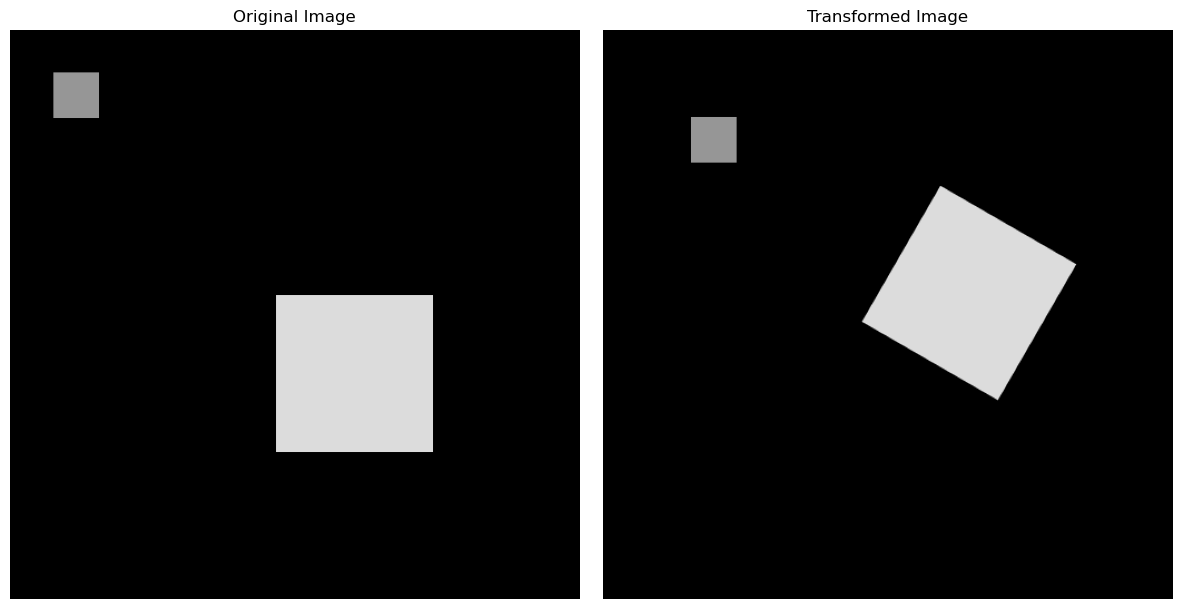

In [26]:
# Combine results
final_image = large_sq + small_sq

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(ex4_image, cmap='gray', vmin=0, vmax=255)
plt.title('Original Image', fontsize=12)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(final_image, cmap='gray', vmin=0, vmax=255)
plt.title('Transformed Image', fontsize=12)
plt.axis('off')

plt.tight_layout()
#plt.savefig('./results/q4compare.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

## Question 5

For the image skeleton.gif, try to modify the normalized image using the following functions: 

<img src="./imgs/functions.png" width="500" height="250"/>

Show the results in each case. Which function produces the best result in your opinion? Discuss your 
results.

You can see the original form of the image below:

<img src="./imgs/skeleton.gif" width="200" height="200"/>

In [27]:
def firstfunc(img, c=1):
    img = np.exp(c * img)
    img = minmax_normalize(img)
    return img

def secondfunc(img, c=1):
    img = c * np.log10(img + 1)
    return img

def thirdfunc(img):
    img = np.where(img < 0.1, img, 2 * img)
    img = minmax_normalize(img)
    return img

In [28]:
cap = cv2.VideoCapture("./imgs/skeleton.gif")
_, ex5_image = cap.read()
cap.release()
ex5_image = cv2.cvtColor(ex5_image, cv2.COLOR_BGR2GRAY)
ex5_image_normal = minmax_normalize(ex5_image)

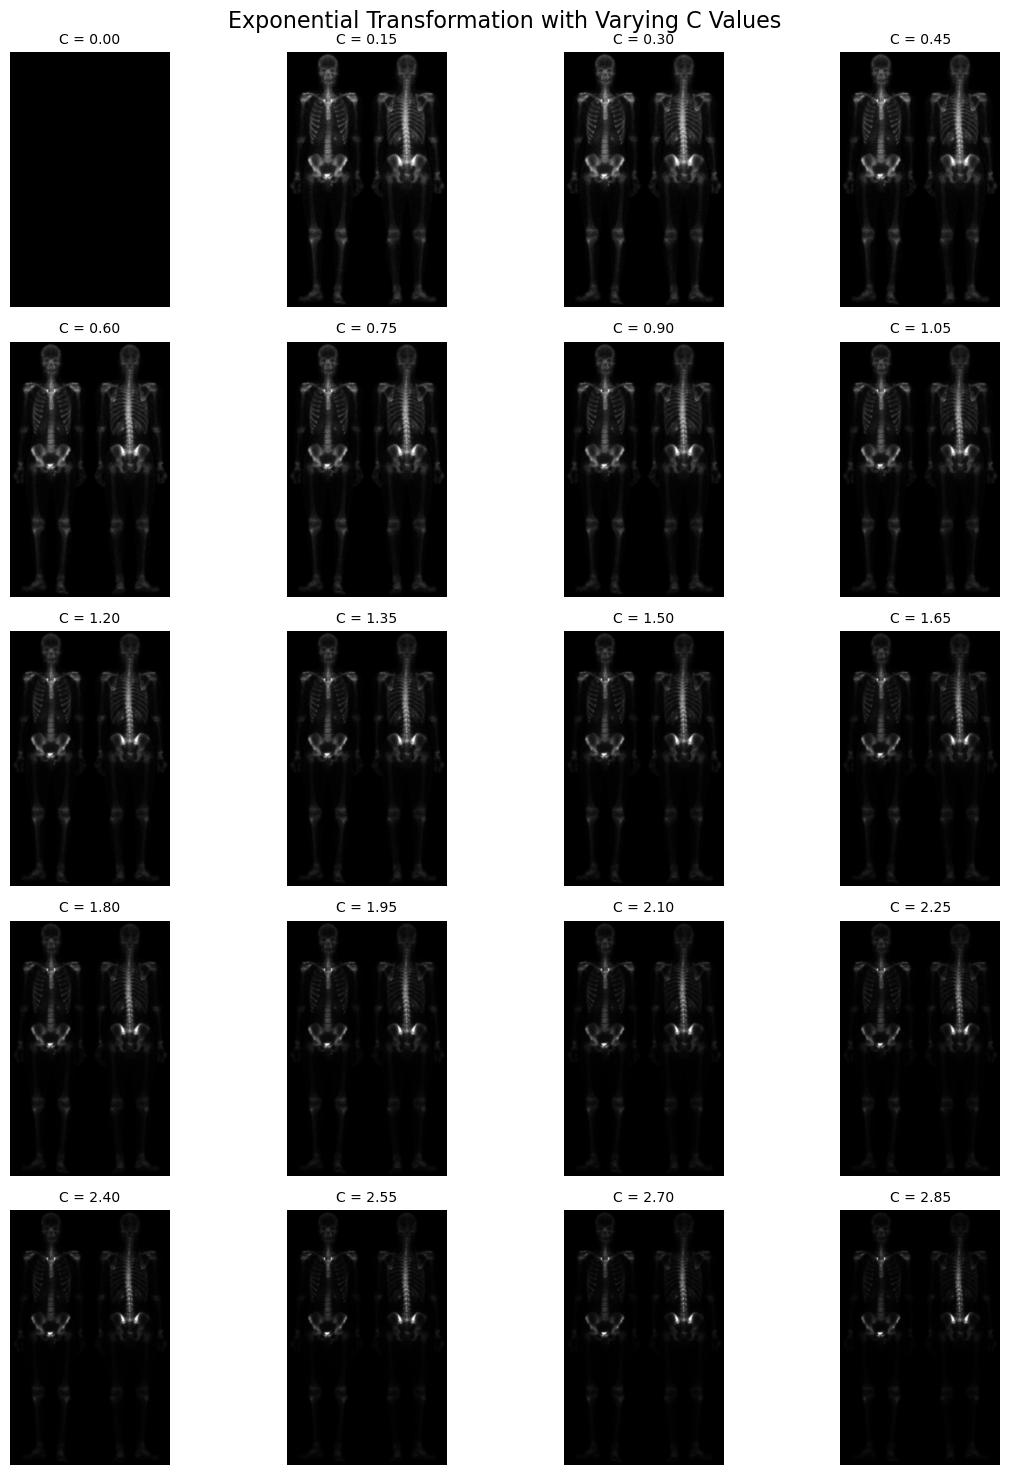

In [29]:
# Generate images with varying C values for first function

c_values = np.arange(0, 3, 0.15)  # C values from 0 to 2.85 in steps of 0.15
transformed_images = [firstfunc(ex5_image_normal, c) for c in c_values]

fig, axs = plt.subplots(5, 4, figsize=(12, 15))

for ax, img, c in zip(axs.ravel(), transformed_images, c_values):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"C = {c:.2f}", fontsize=10)
    ax.axis('off')

plt.suptitle("Exponential Transformation with Varying C Values", fontsize=16)
plt.tight_layout()
#plt.savefig('./results/q5 first function.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

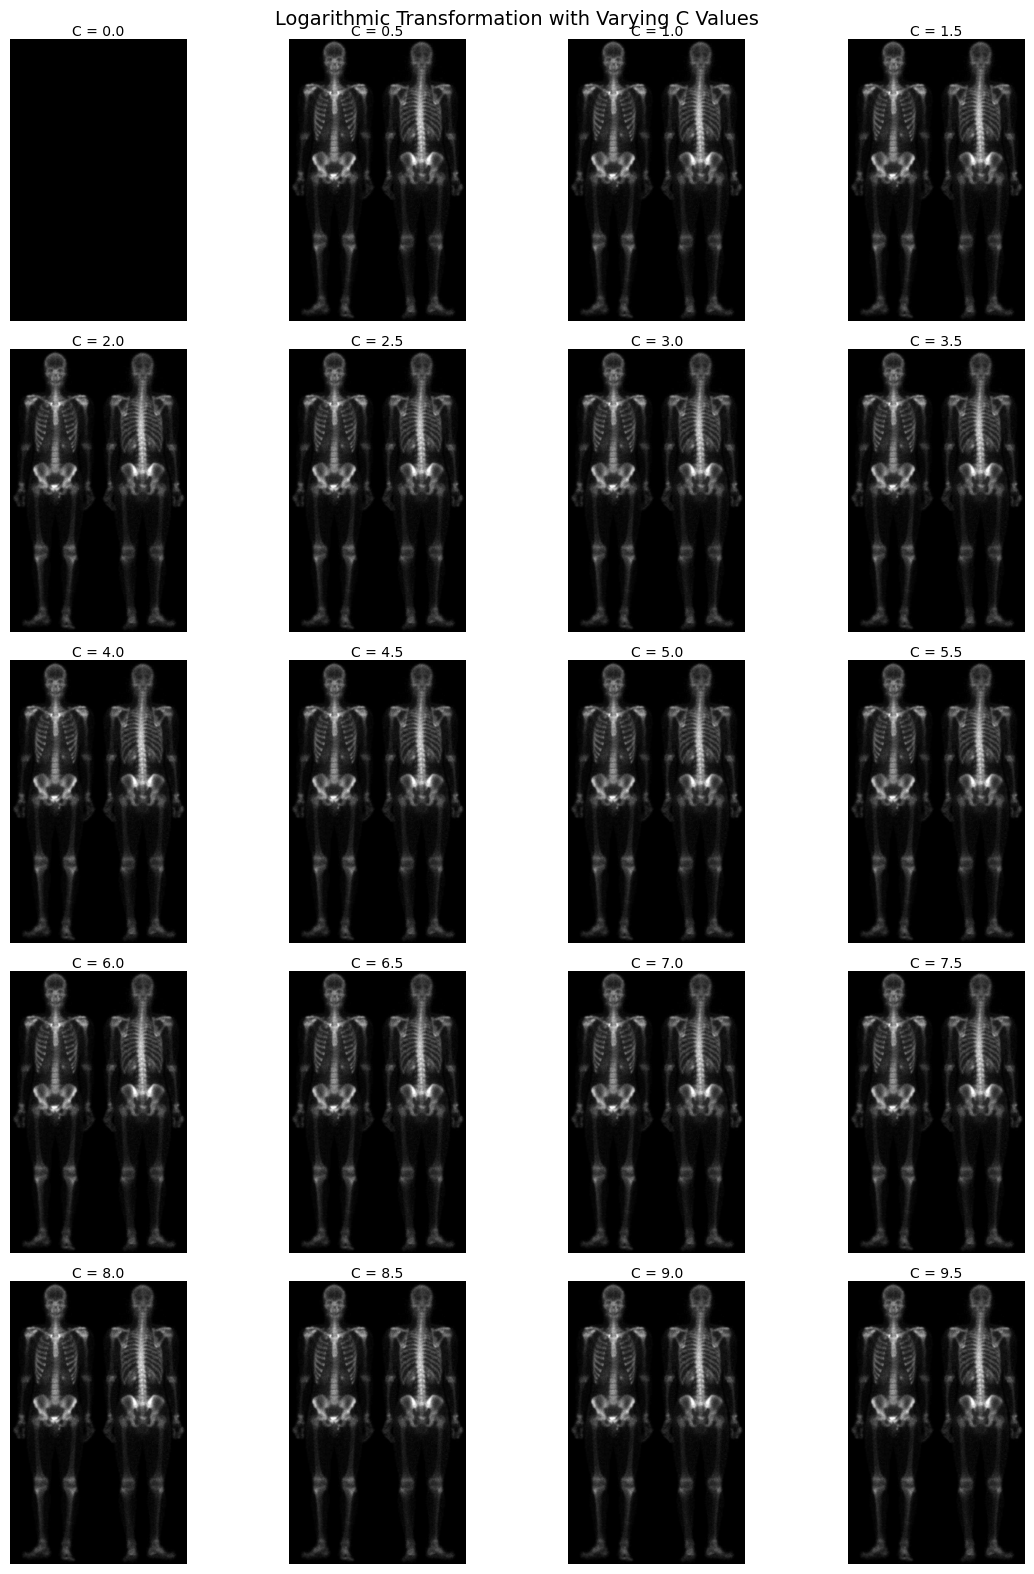

In [30]:
# Generate images with varying C values for second function

c_values = np.arange(0, 10.5, 0.5)  # C values from 0 to 10 in steps of 0.5
log_transforms = [secondfunc(ex5_image_normal, c) for c in c_values]


fig, axs = plt.subplots(5, 4, figsize=(12, 16))

for ax, img, c in zip(axs.ravel(), log_transforms, c_values):
    display_img = minmax_normalize(img) if c > 0 else img
    ax.imshow(display_img, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"C = {c:.1f}", fontsize=10, pad=2)
    ax.axis('off')


plt.suptitle("Logarithmic Transformation with Varying C Values", fontsize=14)
plt.tight_layout(pad=1.0)
#plt.savefig('./results/q5 second function.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

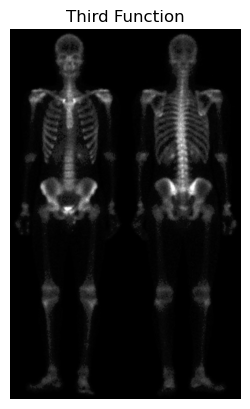

In [31]:
# Enhanced image using third function

plt.imshow(thirdfunc(ex5_image_normal), cmap='gray')
plt.title('Third Function')
plt.axis('off');
#plt.savefig('./results/q5 third function.jpg', format='jpg', bbox_inches="tight", pad_inches=0)

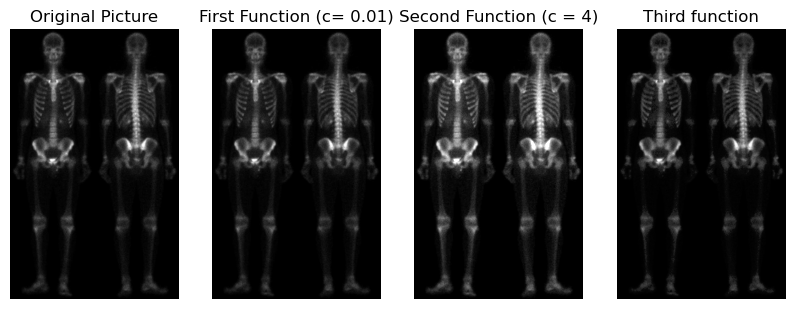

In [32]:
# Comparing the best results of each function
plt.figure(figsize=(10,10))

plt.subplot(1,4,1)
plt.title('Original Picture')
plt.imshow(ex5_image_normal, cmap='gray', vmin=0, vmax=1)
plt.axis('off')

plt.subplot(1,4,2)
plt.title('First Function (c= 0.01)')
plt.imshow(firstfunc(ex5_image_normal, c=0.01), cmap='gray', vmin=0, vmax=1)
plt.axis('off')

plt.subplot(1,4,3)
plt.title('Second Function (c = 4)')
plt.imshow(secondfunc(ex5_image_normal, c=4), cmap='gray', vmin=0, vmax=1)
plt.axis('off')

plt.subplot(1,4,4)
plt.title('Third function')
plt.imshow(thirdfunc(ex5_image_normal), cmap='gray', vmin=0, vmax=1)
plt.axis('off');

#plt.savefig('./results/q5 compare.jpg', format='jpg', bbox_inches="tight", pad_inches=0)